In [1]:
import pandas as pd
import numpy as np

print("================================")
print("RetailFlow - Data Exploration")
print("================================")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

RetailFlow - Data Exploration
Pandas version: 3.1.0
NumPy version: 2.5.4


In [2]:
from pathlib import Path

current_folder = Path.cwd()
project_candidates = (current_folder, current_folder / "RetailFlow", *current_folder.parents)
project_folder = next(
    (folder for folder in project_candidates
     if (folder / "data" / "raw" / "olist_orders_dataset.csv").exists()),
    None,
)

if project_folder is None:
    raise FileNotFoundError(
        "Could not find data/raw/olist_orders_dataset.csv from the current folder."
    )

orders_file = project_folder / "data" / "raw" / "olist_orders_dataset.csv"
print("Project folder:", project_folder)
print("Orders file found:", orders_file.exists())
print("Orders file location:", orders_file)

Project folder: e:\SE Academic Projects\My projects\Data Engineering 01\RetailFlow
Orders file found: True
Orders file location: e:\SE Academic Projects\My projects\Data Engineering 01\RetailFlow\data\raw\olist_orders_dataset.csv


In [3]:
orders = pd.read_csv(orders_file)

print("Orders dataset loaded successfully!")

Orders dataset loaded successfully!


In [4]:
orders.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
print("Number of rows:", orders.shape[0])
print("Number of columns:", orders.shape[1])

Number of rows: 99441
Number of columns: 8


In [6]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [7]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [8]:
missing_values = orders.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [9]:
missing_percentage = (orders.isnull().sum() / len(orders)) * 100

print(missing_percentage.round(2))

order_id                         0.00
customer_id                      0.00
order_status                     0.00
order_purchase_timestamp         0.00
order_approved_at                0.16
order_delivered_carrier_date     1.79
order_delivered_customer_date    2.98
order_estimated_delivery_date    0.00
dtype: float64


In [10]:
duplicate_count = orders.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [11]:
orders["order_status"].unique()

<ArrowStringArray>
[  'delivered',    'invoiced',     'shipped',  'processing', 'unavailable',
    'canceled',     'created',    'approved']
Length: 8, dtype: str

In [12]:
status_counts = orders["order_status"].value_counts()

print(status_counts)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [13]:
status_percentage = (
    orders["order_status"].value_counts(normalize=True) * 100
)

print(status_percentage.round(2))

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64


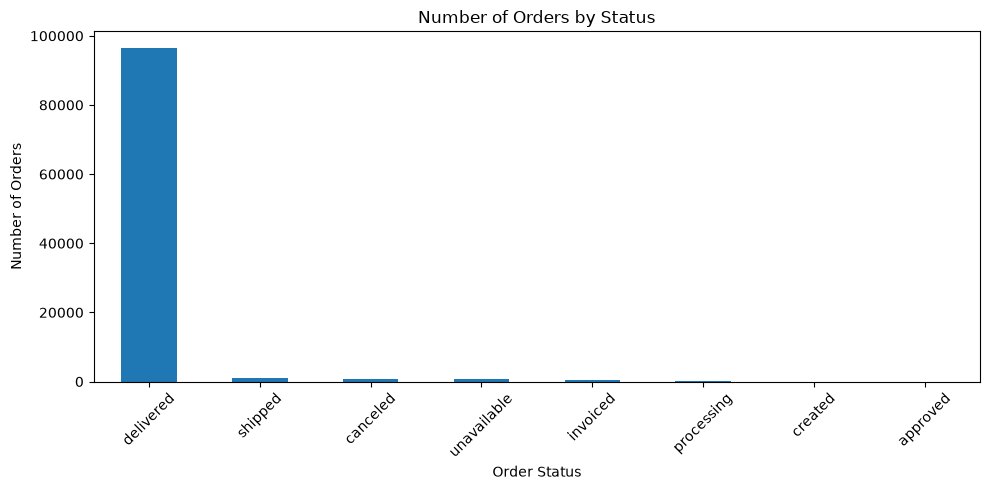

In [14]:
import matplotlib.pyplot as plt

status_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Number of Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
total_orders = len(orders)

delivered_orders = (orders["order_status"] == "delivered").sum()
cancelled_orders = (orders["order_status"] == "canceled").sum()

print("Total Orders:", total_orders)
print("Delivered Orders:", delivered_orders)
print("Cancelled Orders:", cancelled_orders)

print("Delivery Rate:", round(delivered_orders / total_orders * 100, 2), "%")
print("Cancellation Rate:", round(cancelled_orders / total_orders * 100, 2), "%")

Total Orders: 99441
Delivered Orders: 96478
Cancelled Orders: 625
Delivery Rate: 97.02 %
Cancellation Rate: 0.63 %


In [16]:
customers_file = orders_file.parent / "olist_customers_dataset.csv"
order_items_file = orders_file.parent / "olist_order_items_dataset.csv"
payments_file = orders_file.parent / "olist_order_payments_dataset.csv"

customers = pd.read_csv(customers_file)
payments = pd.read_csv(payments_file)
datasets = {"Customers": customers, "Payments": payments}

if order_items_file.exists():
    datasets["Order Items"] = pd.read_csv(order_items_file)
else:
    print(f"Order items dataset not found; skipping it: {order_items_file}")

print("Available datasets loaded successfully:", ", ".join(datasets))

Order items dataset not found; skipping it: e:\SE Academic Projects\My projects\Data Engineering 01\RetailFlow\data\raw\olist_order_items_dataset.csv
Available datasets loaded successfully: Customers, Payments


In [17]:
print("Customers:", customers.shape)
print("Payments:", payments.shape)

Customers: (99441, 5)
Payments: (103886, 5)


In [18]:
print("CUSTOMERS")
print(customers.columns.tolist())


print("\nPAYMENTS")
print(payments.columns.tolist())

CUSTOMERS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

PAYMENTS
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']


In [19]:
print("Unique order IDs:", orders["order_id"].nunique())
print("Total order records:", len(orders))

print("Unique customer IDs:", customers["customer_id"].nunique())
print("Total customer records:", len(customers))

Unique order IDs: 99441
Total order records: 99441
Unique customer IDs: 99441
Total customer records: 99441


In [20]:
for name, df in datasets.items():
    duplicate_count = df.duplicated().sum()

    print(f"{name}: {duplicate_count} duplicate records")

Customers: 0 duplicate records
Payments: 0 duplicate records


In [21]:
# RetailFlow - Data Quality Report

report_datasets = {
    'Orders': orders,
    'Customers': customers,
    'Payments': payments
}
if 'Order Items' in datasets:
    report_datasets['Order Items'] = datasets['Order Items']

for name, df in report_datasets.items():
    print('\n==============================')
    print(name.upper())
    print('==============================')
    print('Total Records:', len(df))
    print('Total Columns:', len(df.columns))
    print('Duplicate Rows:', df.duplicated().sum())
    print('Missing Values:', df.isnull().sum().sum())
    print('\nMissing Values by Column:')
    print(df.isnull().sum())



ORDERS
Total Records: 99441
Total Columns: 8


Duplicate Rows: 0
Missing Values: 4908

Missing Values by Column:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

CUSTOMERS
Total Records: 99441
Total Columns: 5
Duplicate Rows: 0
Missing Values: 0

Missing Values by Column:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

PAYMENTS
Total Records: 103886
Total Columns: 5
Duplicate Rows: 0
Missing Values: 0

Missing Values by Column:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64


In [22]:
# Check Orders and Customers relationship
print('Orders without matching customers:',
      (~orders['customer_id'].isin(customers['customer_id'])).sum())

# Check Order Items and Orders relationship
if 'Order Items' in datasets:
    print('Order items without matching orders:',
          (~datasets['Order Items']['order_id'].isin(orders['order_id'])).sum())

# Check Payments and Orders relationship
print('Payments without matching orders:',
      (~payments['order_id'].isin(orders['order_id'])).sum())


Orders without matching customers: 0
Payments without matching orders: 0
